In [1]:
import gcinfo
import pandas as pd
import matplotlib.pyplot as plt

# World Bank World Development Indicators.
# Annual GDP per capita in constant 2015 US dollars.
df_wide, _ = gcinfo.download_zip(
    "https://api.worldbank.org/v2/en/indicator/NY.GDP.PCAP.KD?downloadformat=csv",
    return_metadata=False,
    data_name="API_NY.GDP.PCAP.KD",
    read_csv_kwargs={"skiprows": 4},
)


Saved to cache\NY.GDP.PCAP.KD.zip


In [2]:
countries = df_wide[df_wide["Country Code"].isin(["CAN", "USA"])].copy()
year_cols = [col for col in countries.columns if str(col).isdigit()]
long = countries.melt(
    id_vars=["Country Name"],
    value_vars=year_cols,
    var_name="Year",
    value_name="GDP per Capita",
)
long["Year"] = long["Year"].astype(int)
long["GDP per Capita"] = pd.to_numeric(long["GDP per Capita"], errors="coerce")
long = long.dropna(subset=["GDP per Capita"])
gdp = (
    long.pivot(index="Year", columns="Country Name", values="GDP per Capita")
    .sort_index()[["Canada", "United States"]]
)
gdp.round(0)


Country Name,Canada,United States
Year,,
1960,15432.0,18992.0
1961,15606.0,19109.0
1962,16456.0,19965.0
1963,17008.0,20546.0
1964,17801.0,21438.0
...,...,...
2021,44639.0,63097.0
2022,45883.0,64322.0
2023,45496.0,65667.0


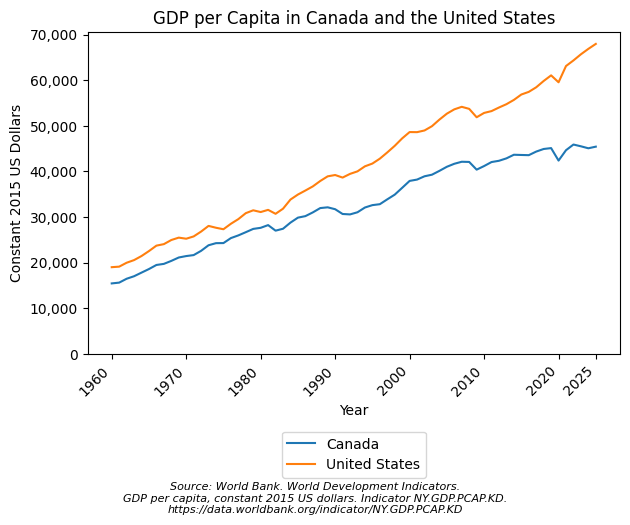

In [3]:
fig, ax = plt.subplots()
for country in ["Canada", "United States"]:
    ax.plot(gdp.index, gdp[country], linestyle="-", label=country)

ax.set_title("GDP per Capita in Canada and the United States")
ax.set_xlabel("Year")
ax.set_ylabel("Constant 2015 US Dollars")
ax.set_ylim(bottom=0)
tick_years = [int(year) for year in gdp.index if int(year) % 10 == 0]
if int(gdp.index.max()) not in tick_years:
    tick_years.append(int(gdp.index.max()))
ax.set_xticks(tick_years)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:,.0f}"))
ax.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=1,
    frameon=True,
)
plt.figtext(
    0.5,
    -0.08,
    "Source: World Bank. World Development Indicators.\n"
    "GDP per capita, constant 2015 US dollars. Indicator NY.GDP.PCAP.KD.\n"
    "https://data.worldbank.org/indicator/NY.GDP.PCAP.KD",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.subplots_adjust(bottom=0.38)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


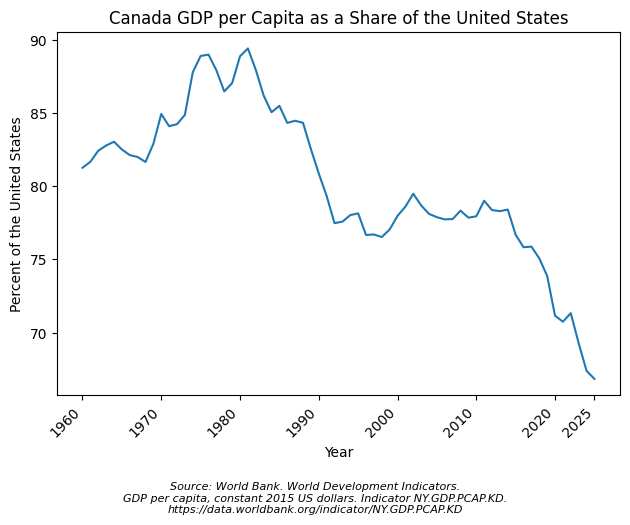

In [4]:
share = gdp["Canada"] / gdp["United States"] * 100

fig, ax = plt.subplots()
ax.plot(share.index, share, linestyle="-")
ax.set_title("Canada GDP per Capita as a Share of the United States")
ax.set_xlabel("Year")
ax.set_ylabel("Percent of the United States")
tick_years = [int(year) for year in share.index if int(year) % 10 == 0]
if int(share.index.max()) not in tick_years:
    tick_years.append(int(share.index.max()))
ax.set_xticks(tick_years)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0f}"))
plt.figtext(
    0.5,
    -0.08,
    "Source: World Bank. World Development Indicators.\n"
    "GDP per capita, constant 2015 US dollars. Indicator NY.GDP.PCAP.KD.\n"
    "https://data.worldbank.org/indicator/NY.GDP.PCAP.KD",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.subplots_adjust(bottom=0.32)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
